<a href="https://colab.research.google.com/github/Daniel220503/Machine-Learning-2026-Agost-Dic/blob/main/Hands_on_4_Perceptron.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hands-on 4: Clasificación en Machine Learning — Clasificadores Lineales: El Perceptrón

**Modalidad:** personal  
**Herramientas:** Python, NumPy, pandas, Matplotlib, seaborn y scikit-learn

## Objetivo
Mostrar **paso a paso** cómo implementar un **Perceptrón** con scikit-learn, siguiendo cada etapa del *pipeline* de Machine Learning, y además construirlo **desde cero** para entender qué hace por dentro.

## Caso de estudio
Usaremos el dataset clásico **Iris** (incluido en scikit-learn, no requiere descargas). El Perceptrón es un clasificador **binario**, así que clasificaremos dos especies: **Iris setosa** (clase 0) contra **Iris versicolor** (clase 1), usando dos características de la flor: **largo y ancho del pétalo**.

## Contenido
1. Fundamentos teóricos del Perceptrón
2. Modelo matemático y analítico
3. Pipeline de Machine Learning
   - 3.1 Recolección de datos
   - 3.2 Descripción y análisis del dataset
   - 3.3 Scatter plot
   - 3.4 Preparación de los datos
   - 3.5 Perceptrón desde cero (NumPy)
   - 3.6 Perceptrón con scikit-learn
   - 3.7 Frontera de decisión
   - 3.8 Predicción
   - 3.9 Evaluación (métricas)
4. Conclusiones

## 1. Fundamentos teóricos del Perceptrón

**Origen:** el Perceptrón fue propuesto por **Frank Rosenblatt en 1957**, inspirado en cómo funciona una neurona biológica. Es el modelo de red neuronal más simple: **una sola neurona artificial**.

**Idea central:** recibe varias entradas numéricas, las multiplica por unos **pesos**, las suma junto con un **sesgo** (*bias*) y, si el resultado supera un umbral, responde **1**; si no, responde **0**.

| Neurona biológica | Perceptrón |
|---|---|
| Dendritas (reciben señales) | Entradas $x_1, x_2, \dots, x_n$ |
| Fuerza de la conexión | Pesos $w_1, w_2, \dots, w_n$ |
| Cuerpo de la neurona | Suma ponderada $z = \mathbf{w}\cdot\mathbf{x} + b$ |
| Dispara o no dispara | Función de activación (escalón) |

**Clasificador lineal:** el Perceptrón separa las clases con una **línea** (en 2D), un **plano** (en 3D) o un **hiperplano** (en más dimensiones). Por eso solo funciona bien cuando los datos son **linealmente separables**.

**Aprendizaje supervisado:** el modelo ve ejemplos con su etiqueta correcta y, cada vez que se equivoca, **corrige sus pesos** un poquito para equivocarse menos la próxima vez.

**Teorema de convergencia del Perceptrón:** si los datos son linealmente separables, el algoritmo **garantiza** encontrar una frontera que los separe en un número finito de pasos. Si no lo son (por ejemplo, el problema XOR), nunca converge.

**Limitaciones:**
- Solo resuelve problemas linealmente separables.
- Es binario (para varias clases se combinan varios perceptrones, estrategia *One-vs-Rest*).
- Entrega solo una clase, no una probabilidad.

**Importancia:** es la base de las redes neuronales modernas. Al apilar muchos perceptrones en capas (con activaciones no lineales) se obtiene el Perceptrón Multicapa (MLP) y, de ahí, el *deep learning*.

## 2. Modelo matemático y analítico

### 2.1 Suma ponderada (entrada neta)

$$z = w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b = \mathbf{w}^\top\mathbf{x} + b$$

donde $\mathbf{x}$ son las características, $\mathbf{w}$ los pesos y $b$ el sesgo.

### 2.2 Función de activación (escalón de Heaviside)

$$\hat{y} = \begin{cases} 1 & \text{si } z \ge 0 \\ 0 & \text{si } z < 0 \end{cases}$$

### 2.3 Frontera de decisión
Es el conjunto de puntos donde $z = 0$. En 2D con dos características:

$$w_1 x_1 + w_2 x_2 + b = 0 \;\;\Rightarrow\;\; x_2 = -\frac{w_1}{w_2}x_1 - \frac{b}{w_2}$$

que es la ecuación de una **recta**. Los puntos de un lado son clase 1 y los del otro, clase 0.

### 2.4 Regla de aprendizaje del Perceptrón
Para cada muestra $(\mathbf{x}_i, y_i)$ se calcula el error $(y_i - \hat{y}_i)$ y se actualiza:

$$w_j \leftarrow w_j + \eta\,(y_i - \hat{y}_i)\,x_{ij} \qquad\qquad b \leftarrow b + \eta\,(y_i - \hat{y}_i)$$

donde $\eta$ es la **tasa de aprendizaje** (*learning rate*).

**Interpretación:**
- Si acierta, $(y_i - \hat{y}_i)=0$ y **no cambia nada**.
- Si predijo 0 y era 1, el error es $+1$ y los pesos **aumentan** hacia $\mathbf{x}_i$ (para que $z$ suba).
- Si predijo 1 y era 0, el error es $-1$ y los pesos **disminuyen** (para que $z$ baje).

### 2.5 Algoritmo
1. Inicializar pesos y sesgo (en cero o valores pequeños).
2. Por cada **época** (pasada completa por los datos) y por cada muestra: calcular $z$, predecir $\hat{y}$ y aplicar la regla de actualización.
3. Repetir hasta que no haya errores o se alcance el máximo de épocas.

### 2.6 Métricas de evaluación
Con la matriz de confusión (VP, VN, FP, FN):

$$Accuracy=\frac{VP+VN}{VP+VN+FP+FN} \quad Precision=\frac{VP}{VP+FP} \quad Recall=\frac{VP}{VP+FN} \quad F1=2\cdot\frac{Precision\cdot Recall}{Precision+Recall}$$

## 3. Pipeline de Machine Learning

Etapas: **recolección → descripción/análisis → visualización → preparación → entrenamiento → predicción → evaluación**.

### 3.0 Importación de librerías

In [ ]:
import numpy as np                                    # NumPy: operaciones numéricas y matrices
import pandas as pd                                   # pandas: manejo de datos en tablas (DataFrame)
import matplotlib.pyplot as plt                       # Matplotlib: gráficas
import seaborn as sns                                 # seaborn: gráficas estadísticas más vistosas
from sklearn.datasets import load_iris                # Función para cargar el dataset Iris incluido en scikit-learn
from sklearn.model_selection import train_test_split  # Divide los datos en entrenamiento y prueba
from sklearn.preprocessing import StandardScaler      # Estandariza las características
from sklearn.linear_model import Perceptron           # El modelo Perceptrón de scikit-learn
from sklearn.metrics import (accuracy_score, precision_score, recall_score,  # Métricas de clasificación
                             f1_score, confusion_matrix, classification_report)  # Matriz de confusión y reporte

np.random.seed(42)                                    # Semilla para que los resultados sean reproducibles
plt.rcParams["figure.figsize"] = (7, 5)               # Tamaño por defecto de las gráficas

### 3.1 Recolección de datos

Cargamos Iris (150 flores, 3 especies, 4 medidas). Como el Perceptrón es binario, **nos quedamos solo con las especies 0 (setosa) y 1 (versicolor)** y con las dos características del **pétalo**.

In [ ]:
iris = load_iris()                                          # Carga el dataset Iris (objeto con datos y metadatos)
df_completo = pd.DataFrame(iris.data,                       # Convierte la matriz de medidas en un DataFrame
                           columns=iris.feature_names)      # Usa los nombres originales como encabezados
df_completo["especie"] = iris.target                        # Agrega la columna con la especie (0, 1 o 2)

df = df_completo[df_completo["especie"] < 2].copy()         # Filtra: solo setosa (0) y versicolor (1)
df = df[["petal length (cm)", "petal width (cm)", "especie"]]  # Conserva solo largo/ancho del pétalo y la clase
df.columns = ["largo_petalo", "ancho_petalo", "especie"]    # Renombra las columnas a nombres más simples
nombres_clase = {0: "setosa", 1: "versicolor"}              # Diccionario para traducir el número de clase a nombre
df.head(10)                                                 # Muestra las primeras 10 filas

,largo_petalo,ancho_petalo,especie
0,1.4,0.2,0
1,1.4,0.2,0
2,1.3,0.2,0
3,1.5,0.2,0
4,1.4,0.2,0
5,1.7,0.4,0
6,1.4,0.3,0
7,1.5,0.2,0
8,1.4,0.2,0
9,1.5,0.1,0


### 3.2 Descripción y análisis del dataset

In [ ]:
print("Dimensiones (filas, columnas):", df.shape)           # Cuántas observaciones y columnas hay
print("\nValores nulos por columna:")                       # Encabezado informativo
print(df.isnull().sum())                                    # Cuenta los valores faltantes por columna
print("\nDistribución de clases:")                          # Encabezado informativo
print(df["especie"].map(nombres_clase).value_counts())      # Cuántas flores hay de cada especie (¿balanceado?)

Dimensiones (filas, columnas): (100, 3)

Valores nulos por columna:
largo_petalo    0
ancho_petalo    0
especie         0
dtype: int64

Distribución de clases:
especie
setosa        50
versicolor    50
Name: count, dtype: int64


In [ ]:
df.groupby("especie")[["largo_petalo", "ancho_petalo"]].describe().T  # Estadísticos descriptivos separados por clase

especie                     0          1
largo_petalo count  50.000000  50.000000
             mean    1.462000   4.260000
             std     0.173664   0.469911
             min     1.000000   3.000000
             25%     1.400000   4.000000
             50%     1.500000   4.350000
             75%     1.575000   4.600000
             max     1.900000   5.100000
ancho_petalo count  50.000000  50.000000
             mean    0.246000   1.326000
             std     0.105386   0.197753
             min     0.100000   1.000000
             25%     0.200000   1.200000
             50%     0.200000   1.300000
             75%     0.300000   1.500000
             max     0.600000   1.800000

**Interpretación:** las dos clases están **perfectamente balanceadas** (50 y 50) y no hay valores nulos. Además, las medias de los pétalos de setosa son mucho menores que las de versicolor, lo que anticipa que será fácil separarlas.

### 3.3 Scatter plot (diagrama de dispersión)
Es la etapa clave para saber si un clasificador lineal tiene sentido: ¿se puede separar con una recta?

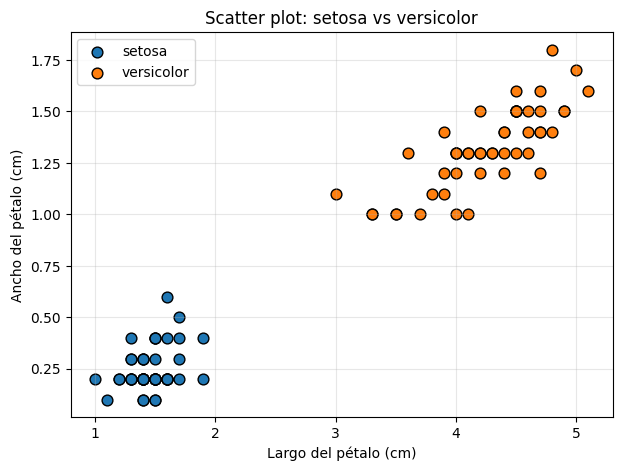

In [ ]:
for clase, color in zip([0, 1], ["tab:blue", "tab:orange"]):          # Recorre cada clase con su color
    sub = df[df["especie"] == clase]                                  # Filtra las flores de esa clase
    plt.scatter(sub["largo_petalo"], sub["ancho_petalo"],             # Dibuja largo (X) contra ancho (Y)
                color=color, edgecolor="k", s=60,                     # Color de la clase, borde negro y tamaño
                label=nombres_clase[clase])                           # Etiqueta para la leyenda
plt.xlabel("Largo del pétalo (cm)")                                   # Etiqueta del eje X
plt.ylabel("Ancho del pétalo (cm)")                                   # Etiqueta del eje Y
plt.title("Scatter plot: setosa vs versicolor")                       # Título de la gráfica
plt.legend()                                                          # Muestra la leyenda
plt.grid(alpha=0.3)                                                   # Cuadrícula suave
plt.show()                                                            # Muestra la gráfica

**Observación:** se forman **dos grupos claramente separados**. Se puede trazar una recta entre ellos sin cometer errores, es decir, los datos son **linealmente separables**. Se cumple la condición para que el Perceptrón converja.

### 3.4 Preparación de los datos
1. Separar las características (**X**) de la etiqueta (**y**).
2. Dividir en entrenamiento (80%) y prueba (20%), **estratificando** para mantener la proporción de clases.
3. **Estandarizar** las características: el Perceptrón es sensible a la escala de las variables.

In [ ]:
X = df[["largo_petalo", "ancho_petalo"]].values                  # Matriz de características (100 filas, 2 columnas)
y = df["especie"].values                                         # Vector de etiquetas (0 o 1)

X_train, X_test, y_train, y_test = train_test_split(             # Divide en entrenamiento y prueba
    X, y, test_size=0.2, random_state=42, stratify=y)            # 20% prueba; semilla fija; mantiene proporción de clases
print("Entrenamiento:", X_train.shape[0], "| Prueba:", X_test.shape[0])  # Tamaño de cada conjunto

Entrenamiento: 80 | Prueba: 20


In [ ]:
scaler = StandardScaler()                                        # Crea el estandarizador (media 0, desviación 1)
X_train_s = scaler.fit_transform(X_train)                        # Aprende media/desviación del entrenamiento y lo transforma
X_test_s = scaler.transform(X_test)                              # Aplica la misma transformación a la prueba
print("Media entrenamiento escalado:", X_train_s.mean(axis=0).round(4))  # Debe ser ≈ 0 en ambas columnas
print("Desv. entrenamiento escalado:", X_train_s.std(axis=0).round(4))   # Debe ser ≈ 1 en ambas columnas

Media entrenamiento escalado: [ 0. -0.]
Desv. entrenamiento escalado: [1. 1.]


### 3.5 Perceptrón desde cero (NumPy)
Antes de usar scikit-learn, implementamos la **regla de aprendizaje de la sección 2.4** para ver exactamente qué ocurre.

In [ ]:
class PerceptronDesdeCero:                                       # Define nuestra propia clase de Perceptrón
    def __init__(self, eta=0.1, epocas=20):                      # Constructor: tasa de aprendizaje y número de épocas
        self.eta = eta                                           # Guarda la tasa de aprendizaje η
        self.epocas = epocas                                     # Guarda el máximo de épocas

    def fit(self, X, y):                                         # Método de entrenamiento
        self.w = np.zeros(X.shape[1])                            # Inicializa los pesos en cero (uno por característica)
        self.b = 0.0                                             # Inicializa el sesgo en cero
        self.errores_por_epoca = []                              # Lista para registrar cuántos errores hay en cada época
        for _ in range(self.epocas):                             # Repite el número de épocas indicado
            errores = 0                                          # Contador de errores de esta época
            for xi, yi in zip(X, y):                             # Recorre cada muestra y su etiqueta
                y_hat = self.predict_uno(xi)                     # Predice la clase de la muestra actual
                actualizacion = self.eta * (yi - y_hat)          # Calcula η·(y − ŷ): cuánto corregir
                self.w += actualizacion * xi                     # Actualiza los pesos: w ← w + η(y−ŷ)x
                self.b += actualizacion                          # Actualiza el sesgo: b ← b + η(y−ŷ)
                errores += int(actualizacion != 0)               # Cuenta 1 error si hubo corrección
            self.errores_por_epoca.append(errores)               # Guarda los errores de la época
        return self                                              # Devuelve el propio objeto

    def entrada_neta(self, X):                                   # Calcula z = w·x + b
        return X @ self.w + self.b                               # Producto punto más el sesgo

    def predict_uno(self, xi):                                   # Predice una sola muestra
        return 1 if (xi @ self.w + self.b) >= 0 else 0           # Función escalón: 1 si z ≥ 0, si no 0

    def predict(self, X):                                        # Predice muchas muestras a la vez
        return np.where(self.entrada_neta(X) >= 0, 1, 0)         # Aplica el escalón a todas las filas

p_cero = PerceptronDesdeCero(eta=0.1, epocas=20).fit(X_train_s, y_train)  # Crea y entrena el modelo desde cero
print("Pesos aprendidos (w):", p_cero.w.round(4))               # Muestra los pesos finales
print("Sesgo aprendido (b):", round(p_cero.b, 4))               # Muestra el sesgo final
print("Errores por época:", p_cero.errores_por_epoca)           # Debe llegar a 0 (convergencia)

Pesos aprendidos (w): [0.1403 0.1083]
Sesgo aprendido (b): 0.0
Errores por época: [2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


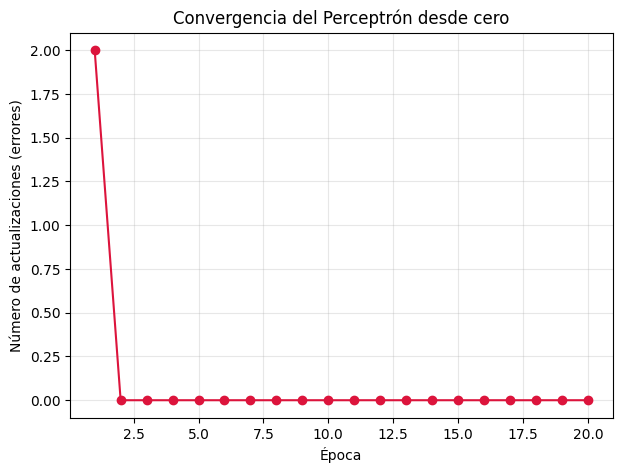

In [ ]:
plt.plot(range(1, len(p_cero.errores_por_epoca) + 1),            # Eje X: número de época
         p_cero.errores_por_epoca, marker="o", color="crimson")  # Eje Y: errores en esa época
plt.xlabel("Época")                                              # Etiqueta del eje X
plt.ylabel("Número de actualizaciones (errores)")                # Etiqueta del eje Y
plt.title("Convergencia del Perceptrón desde cero")              # Título
plt.grid(alpha=0.3)                                              # Cuadrícula
plt.show()                                                       # Muestra la gráfica

**Lectura:** los errores bajan rápidamente hasta llegar a **cero**: el algoritmo **convergió**, tal como garantiza el teorema para datos linealmente separables.

### 3.6 Perceptrón con scikit-learn
Ahora lo mismo, pero con la clase `Perceptron` de scikit-learn.

**Hiperparámetros principales:**
- `eta0`: tasa de aprendizaje.
- `max_iter`: máximo de épocas.
- `tol`: criterio para detenerse cuando ya no mejora.
- `random_state`: semilla para reproducibilidad.

In [ ]:
modelo = Perceptron(eta0=0.1, max_iter=1000,                     # Crea el Perceptrón: tasa 0.1 y hasta 1000 épocas
                    tol=1e-3, random_state=42)                   # Se detiene si no mejora; semilla fija
modelo.fit(X_train_s, y_train)                                   # ENTRENA el modelo con los datos estandarizados

print("Pesos (coef_):", modelo.coef_.round(4))                   # Pesos w aprendidos
print("Sesgo (intercept_):", modelo.intercept_.round(4))         # Sesgo b aprendido
print("Épocas utilizadas:", modelo.n_iter_)                      # Cuántas épocas necesitó para converger

Pesos (coef_): [[0.1147 0.1286]]
Sesgo (intercept_): [0.1]
Épocas utilizadas: 6


### 3.7 Frontera de decisión
Dibujamos la recta $w_1x_1 + w_2x_2 + b = 0$ que aprendió el modelo, sobre los datos originales.

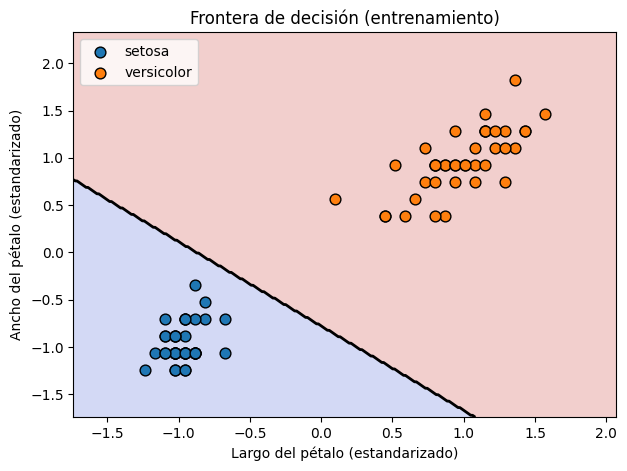

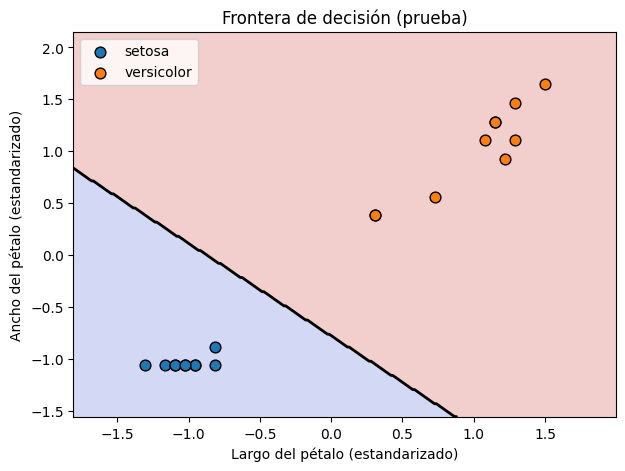

In [ ]:
def graficar_frontera(clf, X_est, y_real, titulo):                       # Función reutilizable para graficar la frontera
    x_min, x_max = X_est[:, 0].min() - 0.5, X_est[:, 0].max() + 0.5      # Límites del eje X con margen
    y_min, y_max = X_est[:, 1].min() - 0.5, X_est[:, 1].max() + 0.5      # Límites del eje Y con margen
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),                 # Crea una malla de puntos que cubre el plano
                         np.linspace(y_min, y_max, 300))                 # (300 x 300 puntos)
    zz = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)    # Predice la clase en cada punto de la malla
    plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")                # Colorea las regiones de cada clase
    plt.contour(xx, yy, zz, levels=[0.5], colors="k", linewidths=2)      # Dibuja la frontera de decisión (línea negra)
    for clase, color in zip([0, 1], ["tab:blue", "tab:orange"]):         # Recorre cada clase
        m = y_real == clase                                              # Máscara de las muestras de esa clase
        plt.scatter(X_est[m, 0], X_est[m, 1], color=color,               # Dibuja los puntos de la clase
                    edgecolor="k", s=60, label=nombres_clase[clase])     # Con borde negro y etiqueta
    plt.xlabel("Largo del pétalo (estandarizado)")                       # Etiqueta del eje X
    plt.ylabel("Ancho del pétalo (estandarizado)")                       # Etiqueta del eje Y
    plt.title(titulo)                                                    # Título recibido como parámetro
    plt.legend()                                                         # Leyenda
    plt.show()                                                           # Muestra la gráfica

graficar_frontera(modelo, X_train_s, y_train, "Frontera de decisión (entrenamiento)")  # Frontera con datos de entrenamiento
graficar_frontera(modelo, X_test_s, y_test, "Frontera de decisión (prueba)")           # Frontera con datos de prueba

### 3.8 Predicción

Calculamos las predicciones sobre el conjunto de prueba y clasificamos una **flor nueva**: pétalo de **1.5 cm de largo y 0.3 cm de ancho**.

In [ ]:
y_pred = modelo.predict(X_test_s)                                # Predice las clases del conjunto de prueba
y_pred_cero = p_cero.predict(X_test_s)                           # Predice con el modelo hecho desde cero
print("Reales    :", y_test)                                     # Etiquetas verdaderas
print("Predichas :", y_pred)                                     # Etiquetas predichas por scikit-learn
print("¿Ambos modelos predicen igual?:", np.array_equal(y_pred, y_pred_cero))  # Compara scikit-learn vs desde cero

Reales    : [1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]
Predichas : [1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]
¿Ambos modelos predicen igual?: True


In [ ]:
flor_nueva = np.array([[1.5, 0.3]])                              # Medidas de la nueva flor (largo, ancho)
flor_nueva_s = scaler.transform(flor_nueva)                      # Se estandariza con el mismo escalador del entrenamiento
z = modelo.decision_function(flor_nueva_s)[0]                    # Entrada neta z = w·x + b
clase = modelo.predict(flor_nueva_s)[0]                          # Clase predicha (0 o 1)
print(f"z = {z:.4f}  →  clase predicha: {nombres_clase[clase]}")  # z<0 → setosa; z≥0 → versicolor

z = -0.1229  →  clase predicha: setosa


### 3.9 Evaluación de la técnica (métricas)

In [ ]:
resultados = pd.DataFrame({                                      # Tabla resumen de métricas
    "Métrica": ["Accuracy", "Precision", "Recall", "F1-score"],  # Nombres de las métricas
    "Entrenamiento": [accuracy_score(y_train, modelo.predict(X_train_s)),    # Exactitud en entrenamiento
                      precision_score(y_train, modelo.predict(X_train_s)),   # Precisión en entrenamiento
                      recall_score(y_train, modelo.predict(X_train_s)),      # Sensibilidad en entrenamiento
                      f1_score(y_train, modelo.predict(X_train_s))],         # F1 en entrenamiento
    "Prueba": [accuracy_score(y_test, y_pred),                   # Exactitud en prueba
               precision_score(y_test, y_pred),                  # Precisión en prueba
               recall_score(y_test, y_pred),                     # Sensibilidad en prueba
               f1_score(y_test, y_pred)]                         # F1 en prueba
}).round(4)                                                      # Redondeo a 4 decimales
resultados                                                       # Muestra la tabla

,Métrica,Entrenamiento,Prueba
0,Accuracy,1.0,1.0
1,Precision,1.0,1.0
2,Recall,1.0,1.0
3,F1-score,1.0,1.0


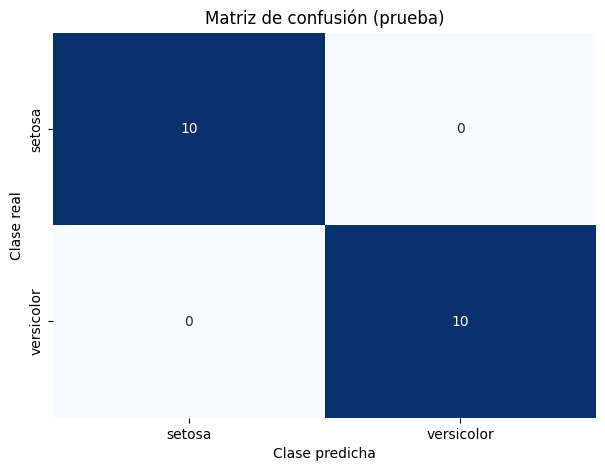

In [ ]:
cm = confusion_matrix(y_test, y_pred)                            # Calcula la matriz de confusión del conjunto de prueba
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,   # Dibuja la matriz como mapa de calor con números
            xticklabels=["setosa", "versicolor"],                # Etiquetas de las columnas (predicho)
            yticklabels=["setosa", "versicolor"])                # Etiquetas de las filas (real)
plt.xlabel("Clase predicha")                                     # Etiqueta del eje X
plt.ylabel("Clase real")                                         # Etiqueta del eje Y
plt.title("Matriz de confusión (prueba)")                        # Título
plt.show()                                                       # Muestra la gráfica

In [ ]:
print(classification_report(y_test, y_pred,                      # Reporte completo por clase
                            target_names=["setosa", "versicolor"]))  # Con los nombres de las especies

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20



**Cómo leer las métricas:**
- **Accuracy:** porcentaje total de aciertos.
- **Precision:** de lo que el modelo dijo "versicolor", cuánto realmente lo era.
- **Recall:** de todas las versicolor reales, cuántas encontró el modelo.
- **F1:** promedio armónico entre precision y recall.
- **Matriz de confusión:** la diagonal son los aciertos; fuera de la diagonal, los errores.

Un resultado perfecto aquí es **esperable**: las clases son linealmente separables y bastante distantes. Con datos que se traslapan, el Perceptrón no alcanzaría el 100%.

## 4. Conclusiones

1. El **Perceptrón** es un clasificador lineal binario formado por una sola neurona: calcula $z=\mathbf{w}^\top\mathbf{x}+b$ y aplica una función escalón.
2. Aprende corrigiendo sus pesos cada vez que se equivoca, con la regla $w \leftarrow w + \eta(y-\hat{y})x$.
3. El **scatter plot** mostró que setosa y versicolor son **linealmente separables**, condición necesaria para que el Perceptrón converja; la gráfica de errores por época lo confirmó (llegó a cero).
4. La implementación **desde cero** y la de **scikit-learn** produjeron predicciones equivalentes, lo que valida que se entiende el modelo matemático.
5. La evaluación con accuracy, precision, recall, F1 y matriz de confusión mostró un desempeño excelente, tanto en entrenamiento como en prueba.
6. **Limitación:** si los datos no son linealmente separables (como versicolor vs virginica, que se traslapan, o el problema XOR), el Perceptrón simple no converge. Para esos casos se usan modelos más potentes, como el Perceptrón Multicapa o SVM con kernel.

## Referencias
- Rosenblatt, F. (1958). *The perceptron: a probabilistic model for information storage and organization in the brain*. Psychological Review, 65(6), 386–408.
- Fisher, R. A. (1936). *The use of multiple measurements in taxonomic problems* (dataset Iris).
- Pedregosa et al. (2011). *Scikit-learn: Machine Learning in Python*. JMLR 12, 2825–2830.